Fetching financial data...

HISTORICAL PERFORMANCE


,Revenue,EBIT,Revenue Growth (%),EBIT Margin (%)
2023-09-30,3.832850e+11,1.143010e+11,NaN,29.82
2024-09-30,3.910350e+11,1.232160e+11,2.02,31.51
2025-09-30,4.161610e+11,1.330500e+11,6.43,31.97
2026-09-30,4.788340e+11,1.580630e+11,15.06,33.01



FIVE YEAR FORECAST


,Year,Revenue,EBIT,EBIAT,D&A,CapEx,Free Cash Flow
0,1,5.163543e+11,1.660785e+11,1.312020e+11,1.487370e+10,1.304160e+10,1.330341e+11
1,2,5.568146e+11,1.790920e+11,1.414827e+11,1.603917e+10,1.406350e+10,1.434584e+11
2,3,6.004453e+11,1.931252e+11,1.525689e+11,1.729597e+10,1.516549e+10,1.546994e+11
3,4,6.474948e+11,2.082581e+11,1.645239e+11,1.865124e+10,1.635382e+10,1.668213e+11
4,5,6.982310e+11,2.245767e+11,1.774156e+11,2.011270e+10,1.763527e+10,1.798930e+11




VALUATION SUMMARY
Company: Apple Inc.
Ticker: AAPL

Average Revenue Growth: 7.84%
Average EBIT Margin: 32.16%

Present Value of FCF: 581,369,302,400.48
Present Value of Terminal Value: 1,643,577,187,454.98

Enterprise Value: 2,224,946,489,855.46
Total Debt: 80,111,000,000.00
Cash: 36,305,000,000.00
Equity Value: 2,181,140,489,855.46

Intrinsic Share Price: 150.09
Current Market Price: 349.97
Estimated Upside/Downside: -57.11%




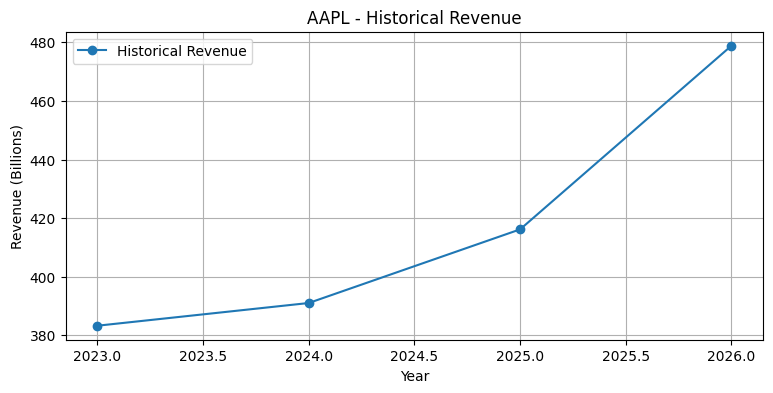

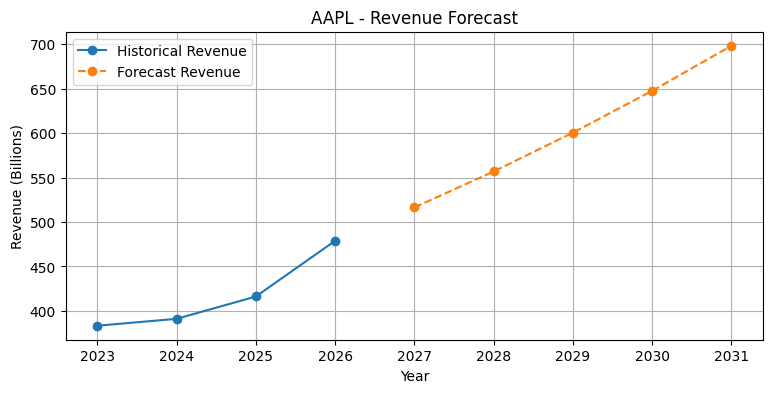

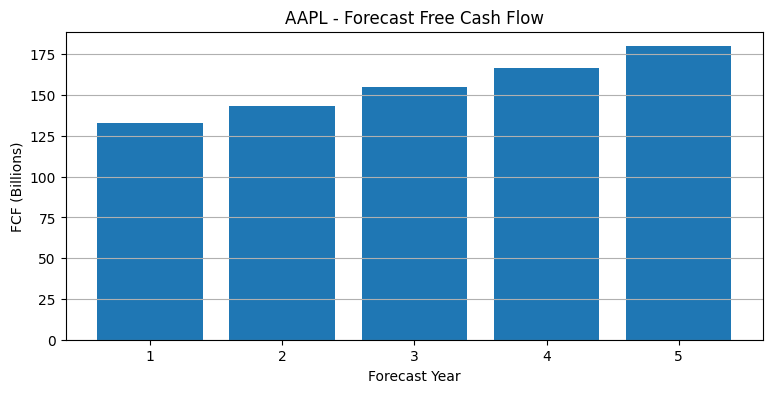


Forecast CSV file saved successfully.


In [ ]:
!pip -q install -U yfinance pandas numpy matplotlib

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")


# 1. USER INPUTS

TICKER = "AAPL"       # Example: AAPL, MSFT, TCS.NS
FORECAST_YEARS = 5
WACC = 0.10
TERMINAL_GROWTH = 0.03
TAX_RATE = 0.21

# 2. FETCH FINANCIAL DATA

print("Fetching financial data...")

stock = yf.Ticker(TICKER)

income = stock.income_stmt
cashflow = stock.cash_flow
balance = stock.balance_sheet
info = stock.info

if income.empty or cashflow.empty:
    raise ValueError("Financial data unavailable for this ticker.")

# Helper function to find financial statement rows
def get_series(data, possible_names):

    for name in possible_names:

        if name in data.index:

            values = pd.to_numeric(
                data.loc[name],
                errors="coerce"
            ).dropna()

            return values.sort_index()

    return pd.Series(dtype=float)


# 3. FINANCIAL PERFORMANCE ANALYSIS


revenue = get_series(
    income,
    ["Total Revenue", "Operating Revenue", "Revenue"]
)

ebit = get_series(
    income,
    ["EBIT", "Operating Income"]
)

depreciation = get_series(
    cashflow,
    [
        "Depreciation And Amortization",
        "Depreciation Amortization Depletion"
    ]
)

capex = get_series(
    cashflow,
    [
        "Capital Expenditure",
        "Capital Expenditures"
    ]
)

historical = pd.concat(
    [
        revenue.rename("Revenue"),
        ebit.rename("EBIT")
    ],
    axis=1
).dropna().sort_index()

if len(historical) < 2:
    raise ValueError("Not enough historical revenue and EBIT data.")

historical["Revenue Growth (%)"] = (
    historical["Revenue"].pct_change() * 100
)

historical["EBIT Margin (%)"] = (
    historical["EBIT"] / historical["Revenue"] * 100
)

print("\nHISTORICAL PERFORMANCE")

display(historical.round(2))



# 4. REVENUE GROWTH & FORECASTING


recent_growth = (
    historical["Revenue Growth (%)"]
    .dropna()
    .tail(3)
)

if recent_growth.empty:
    raise ValueError("Unable to calculate revenue growth.")

# Average of recent historical growth rates
revenue_growth = recent_growth.mean() / 100

# Keep forecast assumptions within a reasonable range
revenue_growth = np.clip(revenue_growth, -0.10, 0.25)

# Average EBIT margin of recent years
ebit_margin = (
    historical["EBIT Margin (%)"]
    .tail(3)
    .mean() / 100
)

# Historical D&A and CapEx ratios
common_da = depreciation.index.intersection(revenue.index)
common_capex = capex.index.intersection(revenue.index)

da_ratio = 0.04
capex_ratio = 0.05

if len(common_da) > 0:
    da_ratio = (
        depreciation.loc[common_da].abs().sum()
        / revenue.loc[common_da].sum()
    )

if len(common_capex) > 0:
    capex_ratio = (
        capex.loc[common_capex].abs().sum()
        / revenue.loc[common_capex].sum()
    )

latest_revenue = historical["Revenue"].iloc[-1]

forecast = []
previous_revenue = latest_revenue

for year in range(1, FORECAST_YEARS + 1):

    future_revenue = previous_revenue * (1 + revenue_growth)

    future_ebit = future_revenue * ebit_margin

    taxes = future_ebit * TAX_RATE

    ebiat = future_ebit - taxes

    da = future_revenue * da_ratio

    future_capex = future_revenue * capex_ratio

    # Simplified Free Cash Flow
    fcf = ebiat + da - future_capex

    forecast.append({
        "Year": year,
        "Revenue": future_revenue,
        "EBIT": future_ebit,
        "EBIAT": ebiat,
        "D&A": da,
        "CapEx": future_capex,
        "Free Cash Flow": fcf
    })

    previous_revenue = future_revenue

forecast_df = pd.DataFrame(forecast)

print("\nFIVE YEAR FORECAST")

display(forecast_df.round(2))



# 5. DCF VALUATION


if WACC <= TERMINAL_GROWTH:
    raise ValueError("WACC must be greater than terminal growth.")

# Present value of future cash flows
forecast_df["Discount Factor"] = [
    1 / (1 + WACC) ** year
    for year in forecast_df["Year"]
]

forecast_df["Present Value of FCF"] = (
    forecast_df["Free Cash Flow"]
    * forecast_df["Discount Factor"]
)

pv_of_fcfs = forecast_df["Present Value of FCF"].sum()

# Terminal Value using Gordon Growth Model
terminal_fcf = (
    forecast_df["Free Cash Flow"].iloc[-1]
    * (1 + TERMINAL_GROWTH)
)

terminal_value = (
    terminal_fcf / (WACC - TERMINAL_GROWTH)
)

pv_terminal_value = (
    terminal_value / (1 + WACC) ** FORECAST_YEARS
)

# Enterprise Value
enterprise_value = pv_of_fcfs + pv_terminal_value


# 6. EQUITY VALUE & SHARE PRICE


def get_latest_value(data, possible_names):

    values = get_series(data, possible_names)

    if values.empty:
        return 0.0

    return float(values.iloc[-1])


total_debt = get_latest_value(
    balance,
    [
        "Total Debt",
        "Long Term Debt And Capital Lease Obligation"
    ]
)

cash = get_latest_value(
    balance,
    [
        "Cash And Cash Equivalents",
        "Cash Cash Equivalents And Short Term Investments",
        "Cash And Cash Equivalents And Short Term Investments"
    ]
)

equity_value = enterprise_value - total_debt + cash

shares = info.get("sharesOutstanding")

if not shares or shares <= 0:
    raise ValueError("Shares outstanding unavailable.")

intrinsic_price = equity_value / shares

# Current market price
current_price = stock.fast_info.get("last_price")

if current_price is None:
    current_price = info.get("currentPrice")


# 7. FINAL RESULTS


print("\n")
print("VALUATION SUMMARY")


print(f"Company: {info.get('longName', TICKER)}")
print(f"Ticker: {TICKER}")

print(f"\nAverage Revenue Growth: {revenue_growth*100:.2f}%")
print(f"Average EBIT Margin: {ebit_margin*100:.2f}%")

print(f"\nPresent Value of FCF: {pv_of_fcfs:,.2f}")
print(f"Present Value of Terminal Value: {pv_terminal_value:,.2f}")

print(f"\nEnterprise Value: {enterprise_value:,.2f}")
print(f"Total Debt: {total_debt:,.2f}")
print(f"Cash: {cash:,.2f}")
print(f"Equity Value: {equity_value:,.2f}")

print(f"\nIntrinsic Share Price: {intrinsic_price:,.2f}")

if current_price:
    print(f"Current Market Price: {current_price:,.2f}")

    upside = (
        (intrinsic_price - current_price)
        / current_price
    ) * 100

    print(f"Estimated Upside/Downside: {upside:.2f}%")

print("\n")


# 8. VISUAL ANALYSIS

# Historical Revenue Chart
plt.figure(figsize=(9, 4))

plt.plot(
    historical.index.year,
    historical["Revenue"] / 1e9,
    marker="o",
    label="Historical Revenue"
)

plt.title(f"{TICKER} - Historical Revenue")
plt.xlabel("Year")
plt.ylabel("Revenue (Billions)")
plt.grid(True)
plt.legend()
plt.show()


# Historical vs Forecast Revenue
forecast_years = [
    historical.index[-1].year + year
    for year in range(1, FORECAST_YEARS + 1)
]

plt.figure(figsize=(9, 4))

plt.plot(
    historical.index.year,
    historical["Revenue"] / 1e9,
    marker="o",
    label="Historical Revenue"
)

plt.plot(
    forecast_years,
    forecast_df["Revenue"] / 1e9,
    marker="o",
    linestyle="--",
    label="Forecast Revenue"
)

plt.title(f"{TICKER} - Revenue Forecast")
plt.xlabel("Year")
plt.ylabel("Revenue (Billions)")
plt.grid(True)
plt.legend()
plt.show()


# Forecast Free Cash Flow
plt.figure(figsize=(9, 4))

plt.bar(
    forecast_df["Year"],
    forecast_df["Free Cash Flow"] / 1e9
)

plt.title(f"{TICKER} - Forecast Free Cash Flow")
plt.xlabel("Forecast Year")
plt.ylabel("FCF (Billions)")
plt.grid(axis="y")
plt.show()



# 9. SAVE FORECAST TO CSV


forecast_df.to_csv(
    f"{TICKER}_financial_forecast.csv",
    index=False
)

print("\nForecast CSV file saved successfully.")
